<img width="200" style="float:left" 
     src="https://upload.wikimedia.org/wikipedia/commons/f/f3/Apache_Spark_logo.svg" />

# Lab 17.1 — Flights Analysis, Exploratory Data Analysis with Spark

This notebook is organized in the following sections:

* [Description](#0)
* [Notebook environment setup](#1)
* [Step 1 - Metadata and initial Data Analysis](#2) 
  * [MinIO](#2.1)
  * [DataFrame creation](#2.2)
  * [Metadata and initial Data Analysis](#2.3)
* [Step 2 - Basic Data Profiling](#3)
  * [Timing related columns basic profiling](#3.1)
  * [Flight related columns basic profiling](#3.2)
  * [Issue related columns basic profiling](#3.3)
* [Step 3 - Answer some business questions to improve service](#4)
  * [Ratio of delayed (and no cancelled) flights by severity](#4.1)
  * [Severe delayed flights statistics by type of delay (carrier, weather, NAS, security and lateaircraft)](#4.2)
  * [Top 20 origin airports (and figures) involved in severe delays](#4.3)
* [Environment shutdown](#5)

<a id='0'></a>
## Description
This notebook complements everything we have done with Apache Spark so far, and it can be considered a reference for Exploratory Data Analysis (EDA) with Spark. It should help you **better understand the type of data analysis you are expected to perform in your Group Assignmen**t.

In summary, we will go through the following high-level tasks:

* Environment setup
* **Metadata review and initial data analysis** to better understand the dataset
* **Basic data profiling** to gain deeper insights into the data we will work with
* Answering some **simple business questions**

## Notebook environment setup
Create a folder named `/mda1/reference_analysis` in your Jupyter Notebook environment and place all the files used throughout this exercise inside it. Keeping everything organized in a single location will make it easier to follow the examples and better understand each step of the process:

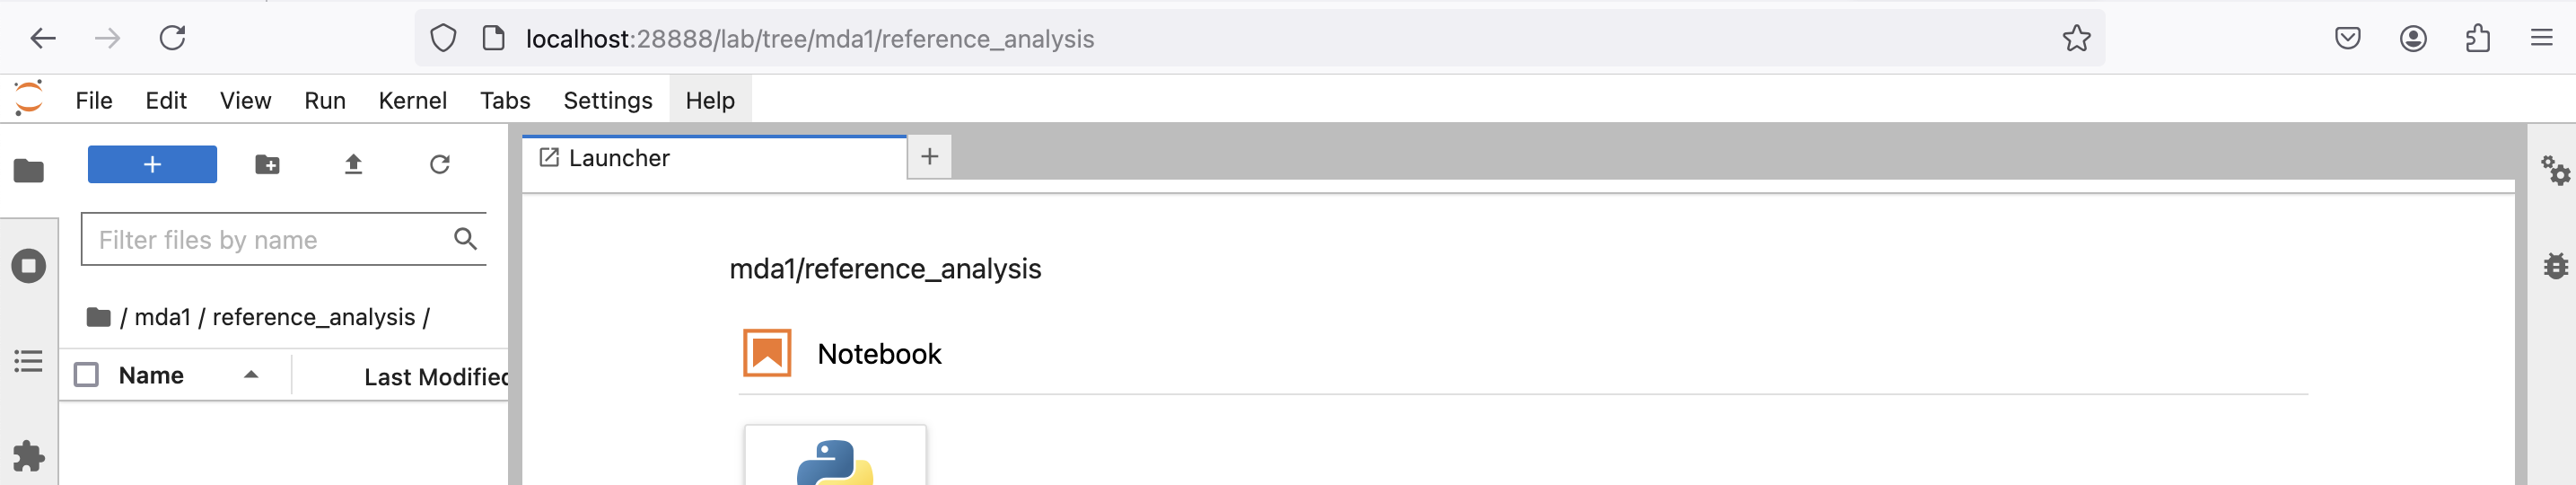

We will use **Pandas** to **display the results in a more readable format**, so let's configure it first:

In [ ]:
import pandas as pd

pd.set_option('display.max_colwidth', None)

Now it's **time to create the [Spark Session](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.SparkSession.html)** before we can do anything else. Remember, the Spark Session *is the entry point for working with Spark through the DataFrame API (the high-level API)*.

In [ ]:
from pyspark.sql.session import SparkSession

spark_session = \
  SparkSession.builder\
              .appName("Flights Analysis, Exploratory Data Analysis with Spark")\
              .getOrCreate()

print(f"This cluster relies on Spark '{spark_session.version}'")

<a id='2'></a>
## Step 1 - Metadata and initial Data Analysis
We are going to **add the dataset we will work with**, `flights_jan08.csv`, **to MinIO**. This notebook shows how to create a DataFrame from files stored in MinIO (object storage) in order to process the data with Spark.

<a id='2.1'></a>
### MinIO

Let’s **start MinIO and make it available** by turning it on from the [OSBDET's Web UI](http://localhost:2026):

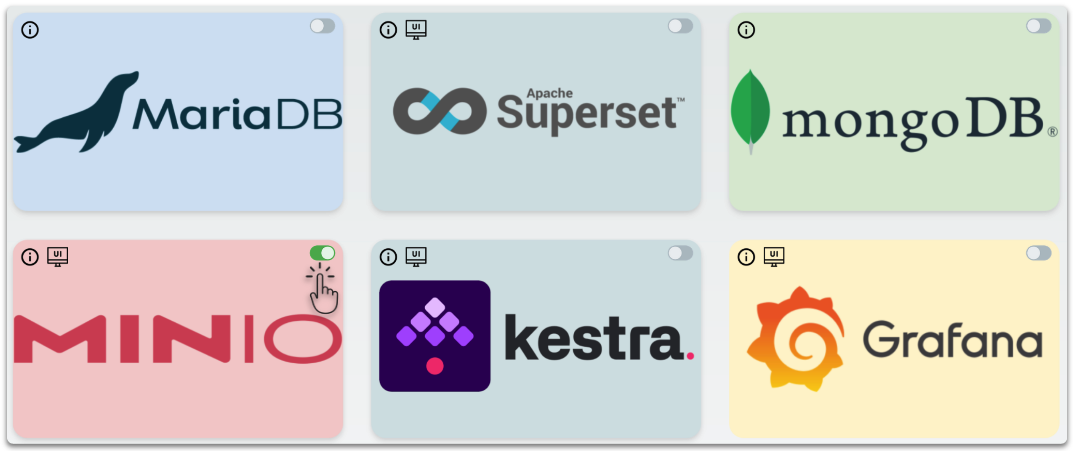

We are going to **upload the `flights_jan08.csv` file to MinIO manually**. Open the [MinIO Administrator UI](http://localhost:29001/buckets) and create the `raw-flights` bucket before uploading the file and continuing with the data analysis:

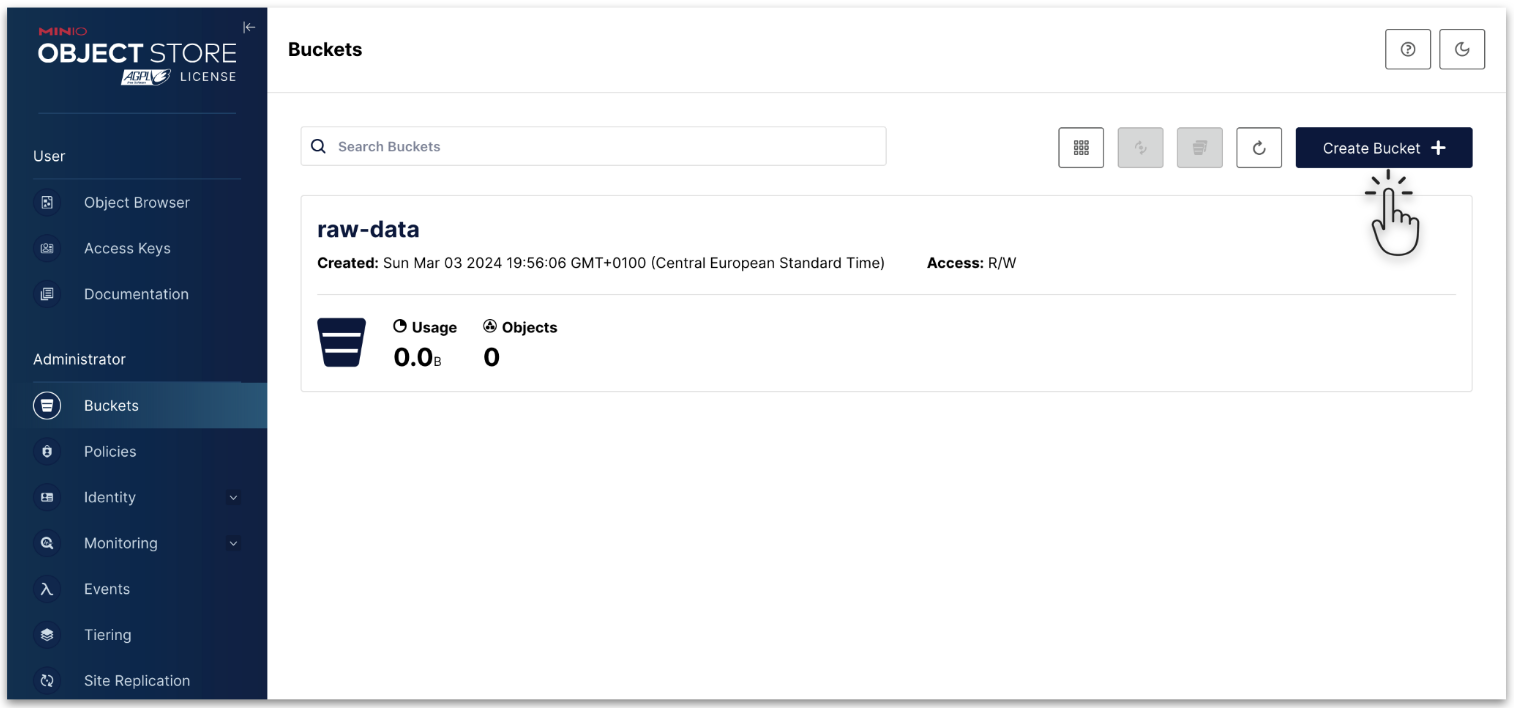

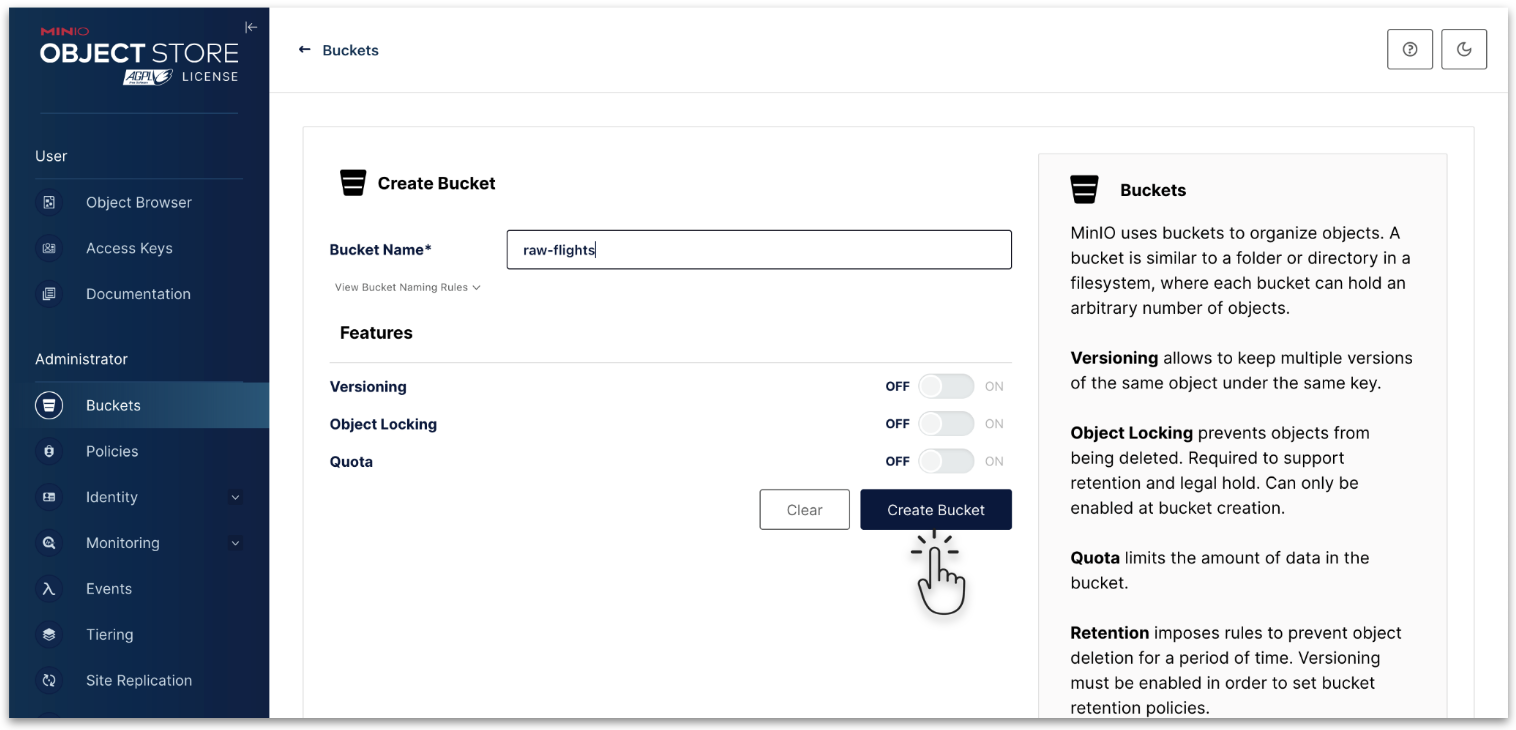

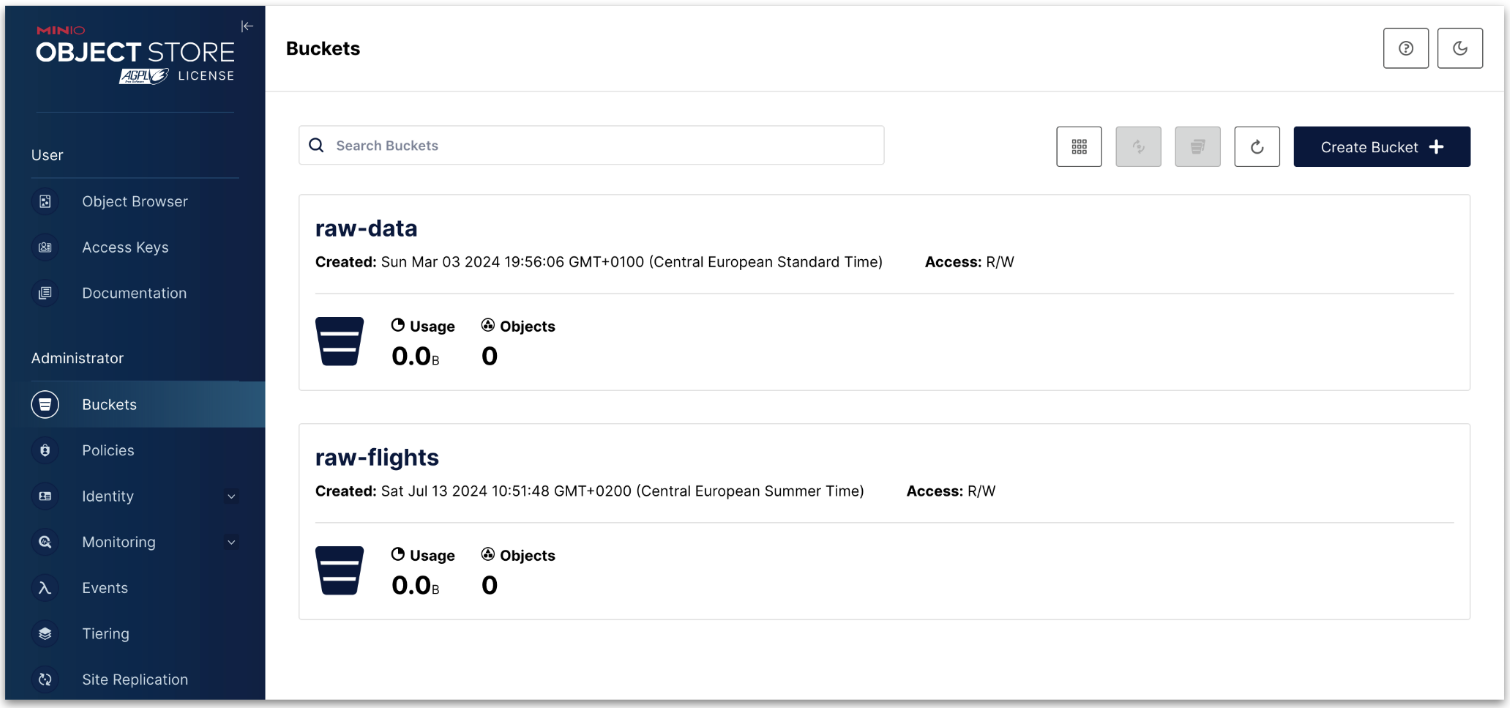

Once the bucket is created, it's time to **upload the file to the bucket**:

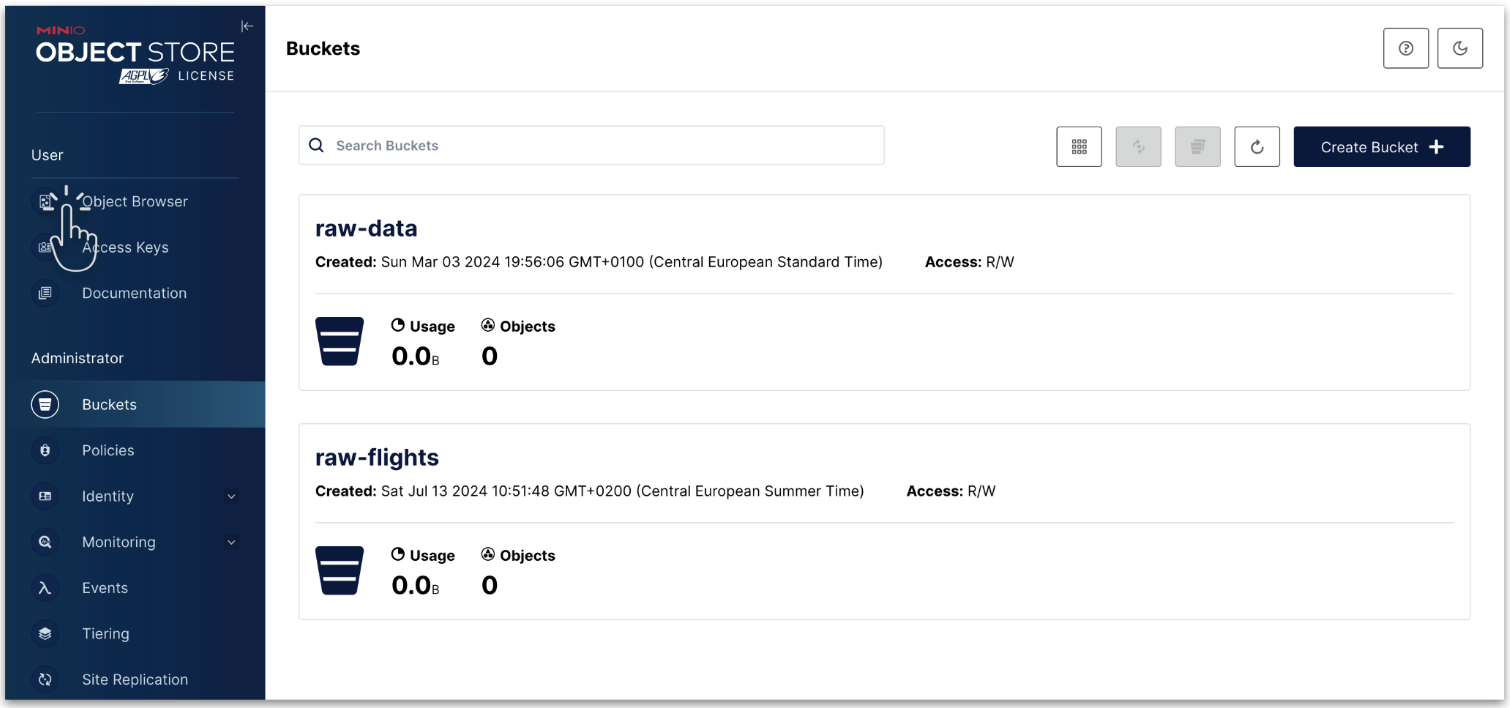

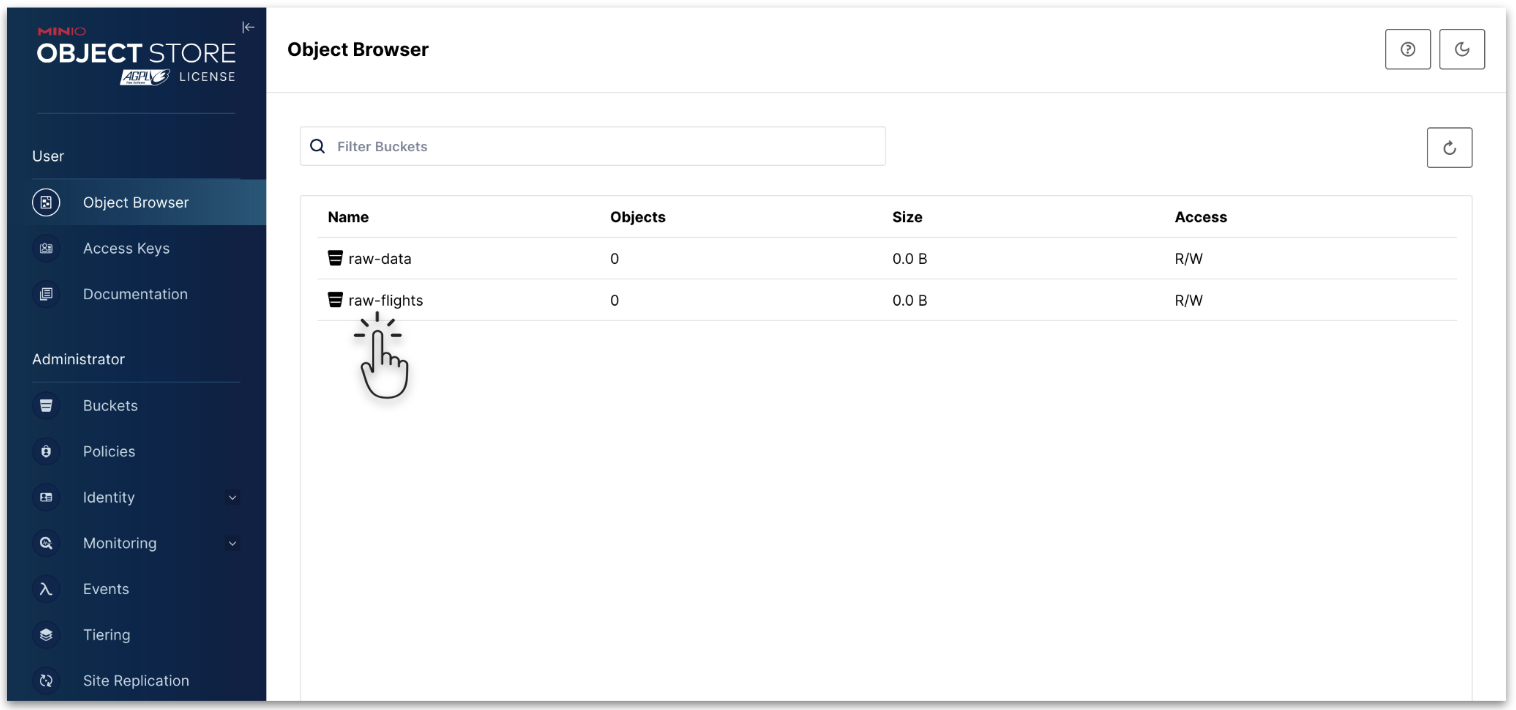

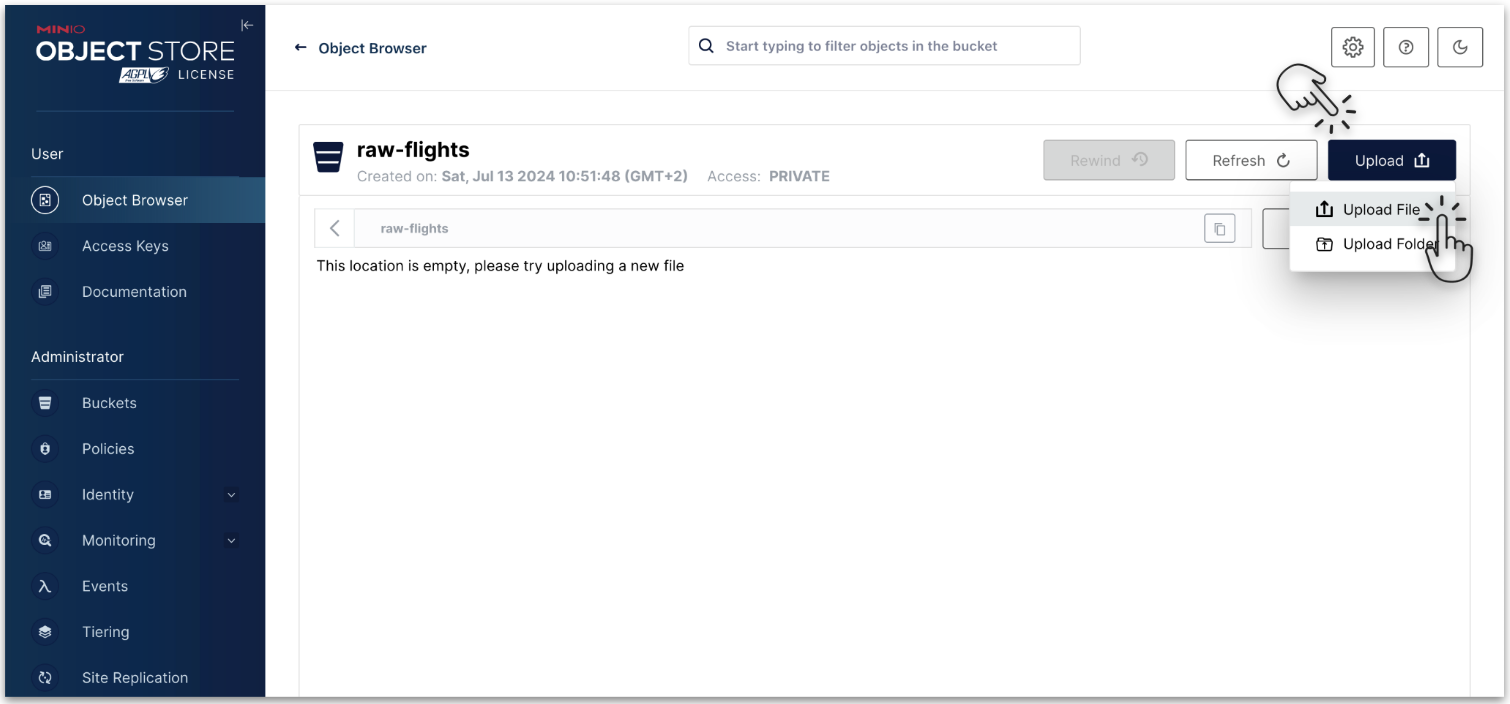

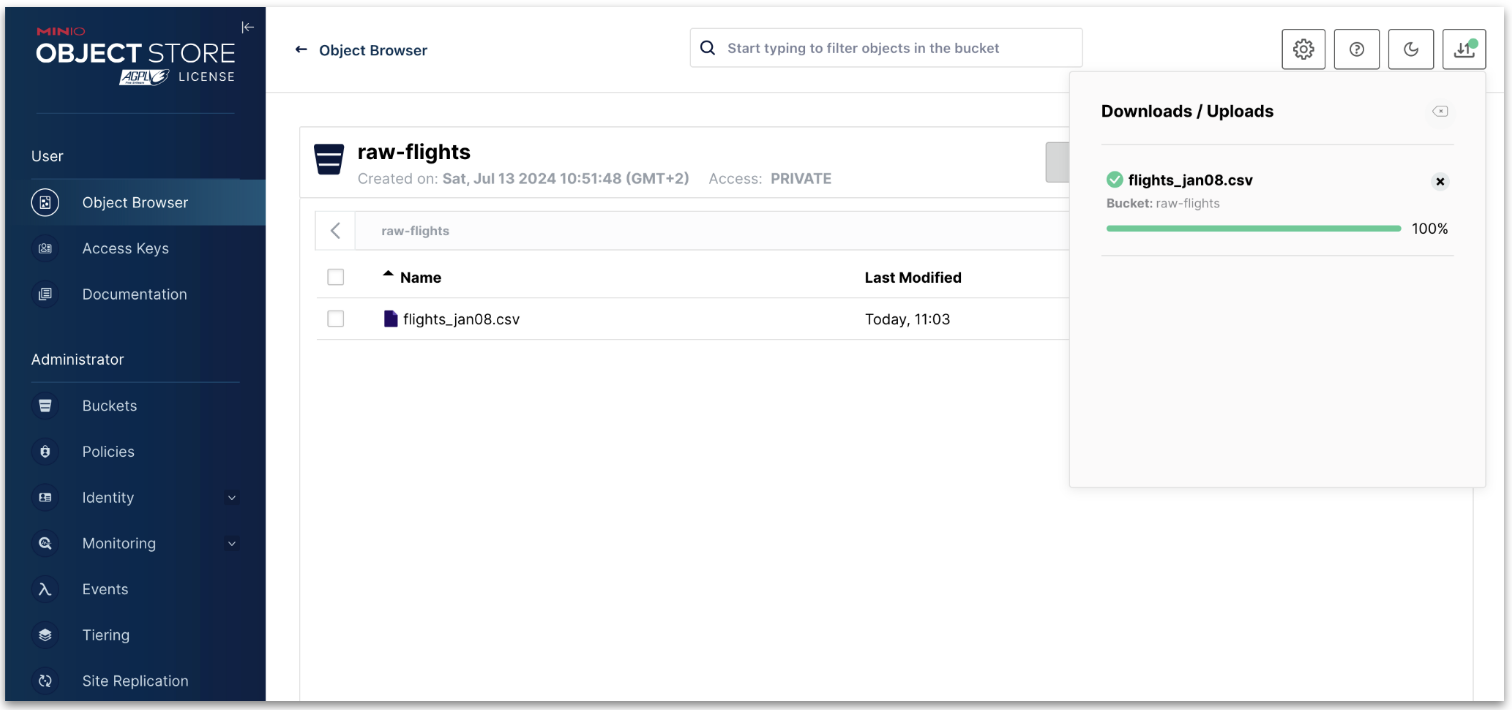

<a id='2.2'></a>
### DataFrame creation
We need to tell the Spark Session **how to access MinIO**, our *S3-compatible object store*:

In [ ]:
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.access.key", "s3access")
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.secret.key", "_s3access123$")
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.path.style.access", "true")
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem")
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.endpoint", "http://localhost:9000")

We are now ready to **create the DataFrame from the data stored in MinIO**, which will allow us to *start the Exploratory Data Analysis (EDA)*:

In [ ]:
flights_raw_df = spark_session.read\
                              .option("header", "true")\
                              .option("inferSchema", "true")\
                              .csv("s3a://raw-flights/*.csv")

<a id='2.3'></a>
### Metadata and initial Data Analysis
#### A. Display schema and size of the DataFrame

In [ ]:
flights_raw_df.printSchema()

In [ ]:
from IPython.display import display, Markdown

display(Markdown("This DataFrame has **%d rows**." % flights_raw_df.count()))

#### B. Get one or multiple random samples from the data set

In [ ]:
# Display the first element in the dataframe
flights_raw_df.limit(1)\
              .toPandas()

In [ ]:
# Ramdomly sample the 10% of dataframe and display the first row
flights_raw_df.sample(0.1)\
              .limit(1)\
              .toPandas()

#### C. Data entities, metrics and dimensions
I identified the following elements:

* **Entities:** Flight (main entity being measured), Airport (dimension), Air Carrier (dimension)
* **Metrics:** Departure time, scheduled departure time, arrival time, scheduled arrival time, etc.
* **Dimensions:** Origin, destination, tail number, flight number, etc.

#### D. Column categorization
The following could be a possible column categorization:

* **Timing-related columns:** `Year`, `Month`, `DayofMonth`, `DayOfWeek`, `DepTime`, `CRSDepTime`, `ArrTime`, and `CRSArrTime`
* **Flight-related columns:** `UniqueCarrier`, `FlightNum`, `TailNum`, `ActualElapsedTime`, `CRSElapsedTime`, `AirTime`, `Origin`, `Dest`, `Distance`, `TaxiIn`, and `TaxiOut`
* **Issue-related columns:** `ArrDelay`, `DepDelay`, `Cancelled`, `CancellationCode`, `Diverted`, `CarrierDelay`, `WeatherDelay`, `NASDelay`, `SecurityDelay`, and `LateAircraftDelay`

<a id='3'></a>
## Step 2 - Basic Data Profiling

<a id='3.1'></a>
### Timing related columns basic profiling

In [ ]:
import pyspark.sql.functions as F

print ("Summary of columns Year, Month, DayofMonth and DayOfWeek:")
flights_raw_df.select("Year","Month","DayofMonth","DayOfWeek")\
              .summary()\
              .toPandas()

In [ ]:
print("Checking for nulls on columns Year, Month, DayofMonth and DayOfWeek:")
flights_raw_df.select( [ F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in ["Year","Month","DayofMonth","DayOfWeek"] ] )\
              .toPandas()

# flights_raw_df.select(F.count(F.when(F.col("Year").isNull(),"Year")).alias("Year"), \
#                       F.count(F.when(F.col("Month").isNull(),"Month")).alias("Month"), \
#                       F.count(F.when(F.col("DayofMonth").isNull(),"DayofMonth")).alias("DayofMonth"), \
#                       F.count(F.when(F.col("DayOfWeek").isNull(),"DayOfWeek")).alias("DayOfWeek")) \
#               .toPandas()

In [ ]:
print("Checking amount of distinct values in columns Year, Month, DayofMonth and DayOfWeek:")
flights_raw_df.select( [ F.countDistinct(c).alias(c) for c in ["Year","Month","DayofMonth","DayOfWeek"] ] )\
              .toPandas()

In [ ]:
print ("Most and least frequent occurrences for DayofMonth and DayOfWeek columns:")
dayofMonthOccurrencesDF = flights_raw_df.groupBy("DayofMonth").count()
dayofMonthOccurrencesDF.orderBy(F.col("count").desc()) \
                       .limit(10)\
                       .toPandas()
dayOfWeekDF = flights_raw_df.groupBy("DayOfWeek").count()
dayOfWeekDF.orderBy(F.col("count").desc()) \
           .limit(10)\
           .toPandas()

leastFreqDayOfMonth    = dayofMonthOccurrencesDF.orderBy(F.col("count").asc()).first()
mostFreqDayOfMonth     = dayofMonthOccurrencesDF.orderBy(F.col("count").desc()).first()
leastFreqDayOfWeek     = dayOfWeekDF.orderBy(F.col("count").asc()).first()
mostFreqDayOfWeek      = dayOfWeekDF.orderBy(F.col("count").desc()).first()

display(Markdown("""
| %s | %s | %s | %s |
|----|----|----|----|
| %s | %s | %s | %s |
""" % ("leastFreqDayOfMonth", "mostFreqDayOfMonth", "leastFreqDayOfWeek", "mostFreqDayOfWeek", \
       "%d (%d occurrences)" % (leastFreqDayOfMonth["DayofMonth"], leastFreqDayOfMonth["count"]), \
       "%d (%d occurrences)" % (mostFreqDayOfMonth["DayofMonth"], mostFreqDayOfMonth["count"]), \
       "%d (%d occurrences)" % (leastFreqDayOfWeek["DayOfWeek"], leastFreqDayOfWeek["count"]), \
       "%d (%d occurrences)" % (mostFreqDayOfWeek["DayOfWeek"], mostFreqDayOfWeek["count"]))))

In [ ]:
print ("Summary of columns DepTime, CRSDepTime, ArrTime and CRSArrTime:")
flights_raw_df.select("DepTime","CRSDepTime","ArrTime","CRSArrTime")\
              .summary()\
              .toPandas()

In [ ]:
print("Checking for nulls on columns DepTime, CRSDepTime, ArrTime and CRSArrTime:")
flights_raw_df.select( [ F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in ["DepTime","CRSDepTime","ArrTime","CRSArrTime"] ] )\
              .toPandas()

In [ ]:
print("Checking amount of distinct values in columns DepTime, CRSDepTime, ArrTime and CRSArrTime:")
flights_raw_df.select([F.countDistinct(c).alias(c) for c in ["DepTime","CRSDepTime","ArrTime","CRSArrTime"]])\
              .toPandas()

<a id='3.2'></a>
### Flight related columns basic profiling

In [ ]:
print ("Summary of columns UniqueCarrier, FlightNum, TailNum, Origin, Dest and Distance:")
flights_raw_df.select("UniqueCarrier", "FlightNum", "TailNum", "Origin", "Dest", "Distance")\
              .summary()\
              .toPandas()

In [ ]:
print("Checking for nulls on columns UniqueCarrier, FlightNum, TailNum, Origin, Dest and Distance:")
flights_raw_df.select( [ F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in ["UniqueCarrier", "FlightNum", "TailNum", "Origin", "Dest", "Distance"] ] )\
              .toPandas()

In [ ]:
print("Checking amount of distinct values in columns UniqueCarrier, FlightNum, TailNum, Origin, Dest and Distance:")
flights_raw_df.select( [ F.countDistinct(c).alias(c) for c in ["UniqueCarrier", "FlightNum", "TailNum", "Origin", "Dest", "Distance"]])\
              .toPandas()

In [ ]:
print ("Most and least frequent occurrences for FlightNum, TailNum, Origin and Dest columns:")
FlightNumDF = flights_raw_df.groupBy("FlightNum").agg(F.count("*").alias("Total"))
TailNumDF   = flights_raw_df.groupBy("TailNum").agg(F.count("*").alias("Total"))
OriginDF    = flights_raw_df.groupBy("Origin").agg(F.count("*").alias("Total"))
DestDF      = flights_raw_df.groupBy("Dest").agg(F.count("*").alias("Total"))

leastFreqFlightNum    = FlightNumDF.orderBy(F.col("Total").asc()).first()
mostFreqFlightNum     = FlightNumDF.orderBy(F.col("Total").desc()).first()
leastFreqTailNum      = TailNumDF.orderBy(F.col("Total").asc()).first()
mostFreqTailNum       = TailNumDF.orderBy(F.col("Total").desc()).first()
leastFreqOrigin       = OriginDF.orderBy(F.col("Total").asc()).first()
mostFreqOrigin        = OriginDF.orderBy(F.col("Total").desc()).first()
leastFreqDest         = DestDF.orderBy(F.col("Total").asc()).first()
mostFreqDest          = DestDF.orderBy(F.col("Total").desc()).first()

display(Markdown("""
| %s | %s | %s | %s |
|----|----|----|----|
| %s | %s | %s | %s |
""" % ("leastFreqFlightNum", "mostFreqFlightNum", "leastFreqTailNum", "mostFreqTailNum", \
       "%d (%d occurrences)" % (leastFreqFlightNum["FlightNum"], leastFreqFlightNum["Total"]), \
       "%d (%d occurrences)" % (mostFreqFlightNum["FlightNum"], mostFreqFlightNum["Total"]), \
       "%s (%d occurrences)" % (leastFreqTailNum["TailNum"], leastFreqTailNum["Total"]), \
       "%s (%d occurrences)" % (mostFreqTailNum["TailNum"], mostFreqTailNum["Total"]))))
display(Markdown("""
| %s | %s | %s | %s |
|----|----|----|----|
| %s | %s | %s | %s |
""" % ("leastFreqOrigin", "mostFreqOrigin", "leastFreqDest", "mostFreqDest", \
       "%s (%d occurrences)" % (leastFreqOrigin["Origin"], leastFreqOrigin["Total"]), \
       "%s (%d occurrences)" % (mostFreqOrigin["Origin"], mostFreqOrigin["Total"]), \
       "%s (%d occurrences)" % (leastFreqDest["Dest"], leastFreqDest["Total"]), \
       "%s (%d occurrences)" % (mostFreqDest["Dest"], mostFreqDest["Total"]))))

In [ ]:
print ("Summary of columns ActualElapsedTime, CRSElapsedTime, AirTime, TaxiIn and TaxiOut:")
flights_raw_df.select("ActualElapsedTime", "CRSElapsedTime", "AirTime", "TaxiIn", "TaxiOut")\
              .summary()\
              .toPandas()

In [ ]:
print("Checking for nulls on columns ActualElapsedTime, CRSElapsedTime, AirTime, TaxiIn and TaxiOut:")
flights_raw_df.select( [ F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in ["ActualElapsedTime", "CRSElapsedTime", "AirTime", "TaxiIn", "TaxiOut"] ] )\
              .toPandas()

In [ ]:
print("Checking amount of distinct values in columns ActualElapsedTime, CRSElapsedTime, AirTime, TaxiIn and TaxiOut:")
flights_raw_df.select( [ F.countDistinct(c).alias(c) for c in ["ActualElapsedTime", "CRSElapsedTime", "AirTime", "TaxiIn", "TaxiOut"] ] )\
              .toPandas()

<a id='3.3'></a>
### Issue related columns basic profiling

In [ ]:
print ("Summary of columns ArrDelay, DepDelay, Cancelled, CancellationCode and Diverted:")
flights_raw_df.select("ArrDelay", "DepDelay", "Cancelled", "CancellationCode", "Diverted")\
              .summary()\
              .toPandas()

In [ ]:
print("Checking for nulls on columns ArrDelay, DepDelay, Cancelled, CancellationCode and Diverted:")
flights_raw_df.select( [ F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in ["ArrDelay", "DepDelay", "Cancelled", "CancellationCode", "Diverted"] ] )\
              .toPandas()

In [ ]:
print("Checking amount of distinct values in columns ArrDelay, DepDelay, Cancelled, CancellationCode and Diverted:")
flights_raw_df.select( [ F.countDistinct(c).alias(c) for c in ["ArrDelay", "DepDelay", "Cancelled", "CancellationCode", "Diverted"]])\
              .toPandas()

In [ ]:
print ("Summary of columns CarrierDelay, WeatherDelay, NASDelay, SecurityDelay and LateAircraftDelay:")
flights_raw_df.select("CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay")\
              .summary()\
              .toPandas()

In [ ]:
print("Checking for nulls on columns CarrierDelay, WeatherDelay, NASDelay, SecurityDelay and LateAircraftDelay:")
flights_raw_df.select( [ F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in ["CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay"] ] )\
              .toPandas()

In [ ]:
print("Checking amount of distinct values in columns CarrierDelay, WeatherDelay, NASDelay, SecurityDelay and LateAircraftDelay:")
flights_raw_df.select( [ F.countDistinct(c).alias(c) for c in ["CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay"] ] )\
              .toPandas()

<a id='4'></a>
## Step 3 - Answer some business questions to improve service
<a id='4.1'></a>
### Ratio of delayed (and no cancelled) flights by severity

In [ ]:
# Delay severity is going to be categorized as follows (totally made up):
#
#   "nodelay"      - delay=(-infinity,0] mins
#   "acceptable"   - delay=(0,15] mins
#   "annoying"     - delay=(15,30] mins
#   "impactful"     - delay=(30,60] mins
#   "unacceptable" - delay=(60,+infinity) mins

# 1. Let's enrich the DF with delay severity based on our categorization
totalFlights = flights_raw_df.count()
delayCategorizationDF = flights_raw_df\
   .where(F.col("ArrDelay")!="NA")\
   .withColumn("DelaySeverity", F.when(F.col("ArrDelay")<=0,"1.nodelay")
                                 .when((F.col("ArrDelay")>0) & (F.col("ArrDelay")<=15),"2.acceptable")\
                                 .when((F.col("ArrDelay")>15) & (F.col("ArrDelay")<=30),"3.annoying")\
                                 .when((F.col("ArrDelay")>30) & (F.col("ArrDelay")<=60),"4.impactful")\
                                 .otherwise("5.unacceptable"))\
    .cache() # optimization to make the processing faster

# 2. Ready to answer to this business question
delayCategorizationDF.where(F.col("Cancelled")==0)\
                     .select("DelaySeverity", "ArrDelay")\
                     .groupBy("DelaySeverity")\
                     .agg(F.count("DelaySeverity").alias("NumFlights"), \
                          (F.count("DelaySeverity")/totalFlights*100).alias("Percentage"))\
                     .orderBy("DelaySeverity")\
                     .select("DelaySeverity","NumFlights", F.round("Percentage",2).alias("RoundedPercentage"))\
                     .toPandas()

<a id='4.2'></a>
### Severe delayed flights statistics by type of delay (carrier, weather, NAS, security and lateaircraft)

In [ ]:
from pyspark.sql.types import IntegerType

# To get statistics of severe delayed flights, we have to prepare the previous DataFrame (delayCategorizationDF):
#   1. Remove cancelled flights
#   2. Keep only severe delayed flights: annoying, impactful and unacceptable
#   3. To get proper statistics, convert String columns with delay info into Integer columns
#      (none of the converted fields contain "NA" as value in severeDelaysDF - you can easily check this out) 
#
severeDelaysDF = delayCategorizationDF\
                       .where((F.col("Cancelled")==0))\
                       .where((F.col("DelaySeverity")!="1.nodelay") & (F.col("DelaySeverity")!="2.acceptable"))\
                       .withColumn("IntArrDelay", F.col("ArrDelay").cast(IntegerType()))\
                       .withColumn("IntCarrierDelay", F.col("CarrierDelay").cast(IntegerType()))\
                       .withColumn("IntWeatherDelay", F.col("WeatherDelay").cast(IntegerType()))\
                       .withColumn("IntNASDelay", F.col("NASDelay").cast(IntegerType()))\
                       .withColumn("IntSecurityDelay", F.col("SecurityDelay").cast(IntegerType()))\
                       .withColumn("IntLateAircraftDelay", F.col("LateAircraftDelay").cast(IntegerType()))\
                       .select("DelaySeverity", "IntArrDelay","IntCarrierDelay","IntWeatherDelay",\
                               "IntNASDelay", "IntSecurityDelay", "IntLateAircraftDelay")\
                       .cache() # optimization to make the processing faster

display(Markdown("**'Arrival' severe delays basic stats** (in mins):"))
severeDelaysDF.groupBy("DelaySeverity")\
              .agg(F.avg("IntArrDelay").alias("AverageDelay"),\
                   F.min("IntArrDelay").alias("LowestDelay"),\
                   F.max("IntArrDelay").alias("HighestDelay"),\
                   F.stddev("IntArrDelay").alias("StdDevDelay"))\
              .orderBy("DelaySeverity")\
              .toPandas()

display(Markdown("**'Carrier' severe delays basic stats** (in mins):"))
severeDelaysDF.groupBy("DelaySeverity")\
              .agg(F.avg("IntCarrierDelay").alias("AverageDelay"),\
                   F.min("IntCarrierDelay").alias("LowestDelay"),\
                   F.max("IntCarrierDelay").alias("HighestDelay"),\
                   F.stddev("IntCarrierDelay").alias("StdDevDelay"))\
              .orderBy("DelaySeverity")\
              .toPandas()

display(Markdown("**'Weather' severe delays basic stats** (in mins):"))
severeDelaysDF.groupBy("DelaySeverity")\
              .agg(F.avg("IntWeatherDelay").alias("AverageDelay"),\
                   F.min("IntWeatherDelay").alias("LowestDelay"),\
                   F.max("IntWeatherDelay").alias("HighestDelay"),\
                   F.stddev("IntWeatherDelay").alias("StdDevDelay"))\
              .orderBy("DelaySeverity")\
              .toPandas()

display(Markdown("**'NAS' severe delays basic stats** (in mins):"))
severeDelaysDF.groupBy("DelaySeverity")\
              .agg(F.avg("IntNASDelay").alias("AverageDelay"),\
                   F.min("IntNASDelay").alias("LowestDelay"),\
                   F.max("IntNASDelay").alias("HighestDelay"),\
                   F.stddev("IntNASDelay").alias("StdDevDelay"))\
              .orderBy("DelaySeverity")\
              .toPandas()

display(Markdown("**'Security' severe delays basic stats** (in mins):"))
severeDelaysDF.groupBy("DelaySeverity")\
              .agg(F.avg("IntSecurityDelay").alias("AverageDelay"),\
                   F.min("IntSecurityDelay").alias("LowestDelay"),\
                   F.max("IntSecurityDelay").alias("HighestDelay"),\
                   F.stddev("IntSecurityDelay").alias("StdDevDelay"))\
              .orderBy("DelaySeverity")\
              .toPandas()

display(Markdown("**'LateAircraft' severe delays basic stats** (in mins):"))
severeDelaysDF.groupBy("DelaySeverity")\
              .agg(F.avg("IntLateAircraftDelay").alias("AverageDelay"),\
                   F.min("IntLateAircraftDelay").alias("LowestDelay"),\
                   F.max("IntLateAircraftDelay").alias("HighestDelay"),\
                   F.stddev("IntLateAircraftDelay").alias("StdDevDelay"))\
              .orderBy("DelaySeverity")\
              .toPandas()

<a id='4.3'></a>
### Top 20 origin airports (and figures) involved in severe delays

In [ ]:
# Our answer to this business question will be:
#   1. List of top 20 origin airports with highest severe delayed (aka unacceptable) flights ratio 
#      (based on total number of flights)
#   2. List of top 20 origin airports with severe delayed flights ratio by severity category (unacceptable,
#      impactful and annoying)

# In order to be able to deliver these insights, we need some preparation:
#   1. Define a DataFrame with total flights per Origin airport (totalFlightsOriginDF)
#   2. Define a DataFrame with aggregated data by Origin and DelaySeverity to figure out
#      number of flights delayed per severity category (severeDelaysOriginDF)
#   3. Combine both DataFrames to come up with one single DataFrame containin total flights
#      per origin airport and number of flights delayed by severity to compute ratios (combinedDF)

totalFlightsOriginDF = \
   flights_raw_df.groupBy("Origin")\
            .agg(F.count("*").alias("TotalFlights"))
severeDelaysOriginDF = \
  delayCategorizationDF.where((F.col("Cancelled")==0))\
                       .where((F.col("DelaySeverity")!="1.nodelay") & (F.col("DelaySeverity")!="2.acceptable"))\
                       .select("Origin", "DelaySeverity")\
                       .groupBy("Origin", "DelaySeverity")\
                       .agg(F.count("*").alias("NumSevereDelayedFlights"))

combinedDF = \
  severeDelaysOriginDF\
     .join(totalFlightsOriginDF, "Origin")\
     .withColumn("SevereDelayedPercentage", F.round(F.col("NumSevereDelayedFlights")/F.col("TotalFlights")*100,2))\
     .orderBy(F.col("SevereDelayedPercentage").desc())\
     .cache() # optimization to make the processing faster

display(Markdown("**Top 20 origin airports** with highest severe delayed (**unacceptable**) flights percentage (in \%):"))
combinedDF.limit(20)\
          .toPandas()
display(Markdown("**Top 20 origin airports with severe delayed flights percentage** by severity category (in \%):"))
combinedDF\
   .groupBy("Origin")\
   .pivot("DelaySeverity")\
   .min("SevereDelayedPercentage")\
   .orderBy(F.col("`5.unacceptable`").desc(), F.col("`4.impactful`").desc(), F.col("`3.annoying`").desc())\
   .limit(20)\
   .toPandas()

<a id='5'></a>
## Environment shutdown

As we are done working with the dataset, let's **stop MinIO to release resources** by switching it off:

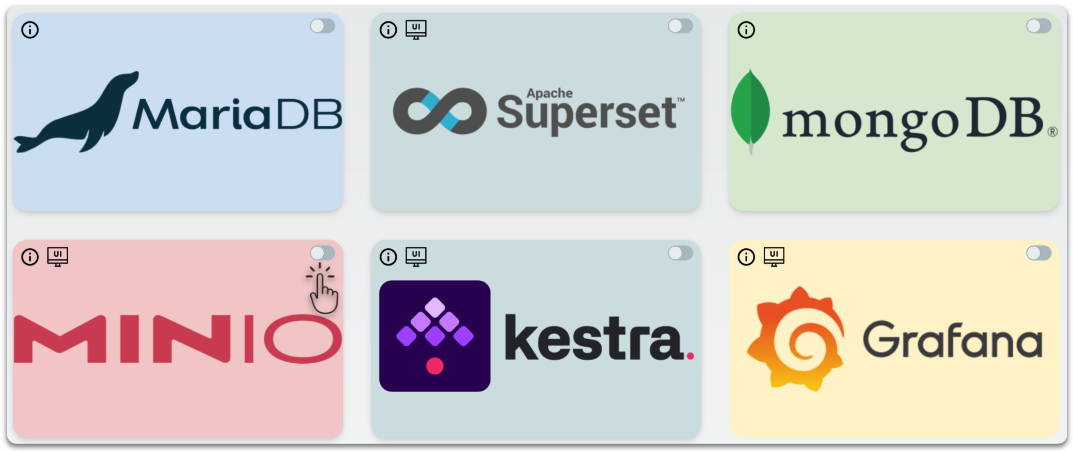

Last but not least, **don't forget to stop your course environment** to release resources and *avoid other applications from being impacted and becoming slow*:

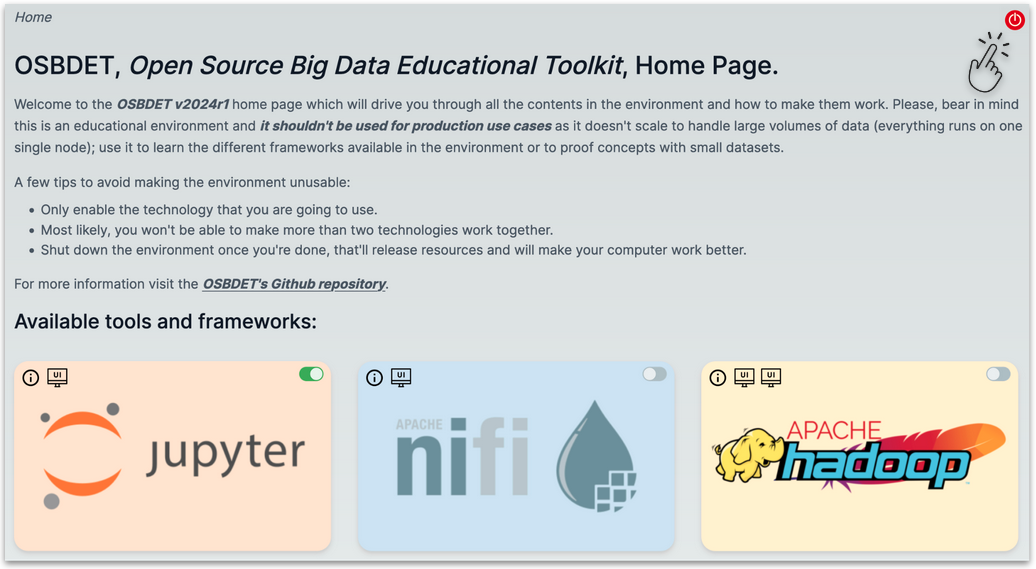